##### Copyright 2026 The Contributors

Licensed under the Apache License, Version 2.0 (the "License");
you may not use this file except in compliance with the License.
See the LICENSE file in the repository root.


# 06 — Operational inference

Score the **most recent** feature month (the one where next month's truth
isn't known yet -- that's the whole point of deploying this) and turn raw
predictions into something a field team can act on: a ranked list, a
High/Medium/Low tier, a plain-English reason, and a JSON export for a
dashboard/map.

## Prerequisites
- Trained models (notebook `04`)
- `artifacts/features.csv` (notebook `01`)


In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
print("ROOT =", ROOT)


ROOT = /Users/froncort.ai/Desktop/Froncort/ai-acf-ml-notebooks


In [2]:
from utils import ARTIFACTS_DIR, load_data, save_data
from pipeline.training import load_models

bundle = load_models()
features = load_data(ARTIFACTS_DIR / "features.csv")
features["month"] = pd.to_datetime(features["month"])
latest_month = features["month"].max()
print(f"Scoring month: {latest_month.date()}  (predicting {(latest_month + pd.DateOffset(months=1)).strftime('%Y-%m')})")


Scoring month: 2025-08-01  (predicting 2025-09)


## Risk tiers

`assign_risk_tier` is a simple, auditable rule on top of the model output --
field teams trust "High = predicted >=3 cases OR (>=1 case AND >=70% gate
probability)" far more than a raw probability number, and a rule is easy to
recalibrate locally without retraining.


In [3]:
from pipeline.inference import assign_risk_tier

demo_cases = [0.2, 1.5, 3.2, 0.8]
demo_gate = [0.2, 0.75, 0.9, 0.5]
for c, g, tier in zip(demo_cases, demo_gate, assign_risk_tier(demo_cases, demo_gate)):
    print(f"predicted_cases={c:<4} gate_probability={g:<4} -> {tier}")


predicted_cases=0.2  gate_probability=0.2  -> Low
predicted_cases=1.5  gate_probability=0.75 -> High
predicted_cases=3.2  gate_probability=0.9  -> High
predicted_cases=0.8  gate_probability=0.5  -> Low


## Generate the ranked recommendation list


In [4]:
from pipeline.inference import generate_recommendations, export_dashboard_json

recs = generate_recommendations(
    features,
    bundle["stage1"],
    bundle["stage2"],
    bundle["feature_cols"],
    calibrator=bundle["calibrator"],
    top_k=30,
)
save_data(recs, ARTIFACTS_DIR / "recommendations.csv")
export_dashboard_json(recs)
print(f"Risk tier breakdown: {recs['risk_tier'].value_counts().to_dict()}")
recs[["rank", "h3_index", "predicted_cases", "gate_probability", "risk_tier", "rationale"]].head(15)


INFO | Recommendations for 2025-08-01: top 30 (High=30)


INFO | Saved 30 rows -> /Users/froncort.ai/Desktop/Froncort/ai-acf-ml-notebooks/artifacts/recommendations.csv


INFO | Dashboard JSON -> /Users/froncort.ai/Desktop/Froncort/ai-acf-ml-notebooks/artifacts/dashboard_recommendations.json


Risk tier breakdown: {'High': 30}


,rank,h3_index,predicted_cases,gate_probability,risk_tier,rationale
0,1,8a6088501647fff,2.432612,0.837209,High,Expected 2.4 cases; Case probability 84%; Rece...
1,2,8a608850e517fff,2.196400,0.821192,High,Expected 2.2 cases; Case probability 82%; Rece...
2,3,8a608850e50ffff,2.019891,0.882812,High,Expected 2.0 cases; Case probability 88%; Rece...
3,4,8a608850ed77fff,1.990173,0.821192,High,Expected 2.0 cases; Case probability 82%; Rece...
4,5,8a608850e80ffff,1.926592,0.821192,High,Expected 1.9 cases; Case probability 82%; Rece...
5,6,8a6088503b4ffff,1.923710,0.837209,High,Expected 1.9 cases; Case probability 84%; Rece...
6,7,8a608850e10ffff,1.915364,0.821192,High,Expected 1.9 cases; Case probability 82%; Rece...
7,8,8a608850ec77fff,1.887502,0.882812,High,Expected 1.9 cases; Case probability 88%; Rece...
8,9,8a6088503a77fff,1.836365,0.882813,High,Expected 1.8 cases; Case probability 88%; Rece...
9,10,8a608850e90ffff,1.832591,0.821192,High,Expected 1.8 cases; Case probability 82%; Rece...


## Reading the rationale

Each recommendation's `rationale` string is built from the same features
the model used -- e.g. "High predicted count (3.2 cases expected); Case
probability 92%; Recent history (2 cases last month); Elevated neighbor
activity". This is deliberately simple (rule-based, not SHAP) so a
non-technical reviewer can immediately see *why* a hexagon was ranked highly,
and challenge it if it looks wrong.


In [5]:
for _, row in recs.head(5).iterrows():
    print(f"#{int(row['rank']):>2}  {row['h3_index']}  [{row['risk_tier']}]")
    print(f"     {row['rationale']}\n")


# 1  8a6088501647fff  [High]
     Expected 2.4 cases; Case probability 84%; Recent history (1 last month); Elevated neighbor activity

# 2  8a608850e517fff  [High]
     Expected 2.2 cases; Case probability 82%; Recent history (1 last month); Elevated neighbor activity

# 3  8a608850e50ffff  [High]
     Expected 2.0 cases; Case probability 88%; Recent history (3 last month); Elevated neighbor activity

# 4  8a608850ed77fff  [High]
     Expected 2.0 cases; Case probability 82%; Recent history (2 last month); Elevated neighbor activity

# 5  8a608850e80ffff  [High]
     Expected 1.9 cases; Case probability 82%; Recent history (2 last month); Elevated neighbor activity



## Bar chart: top hexagons by predicted case count


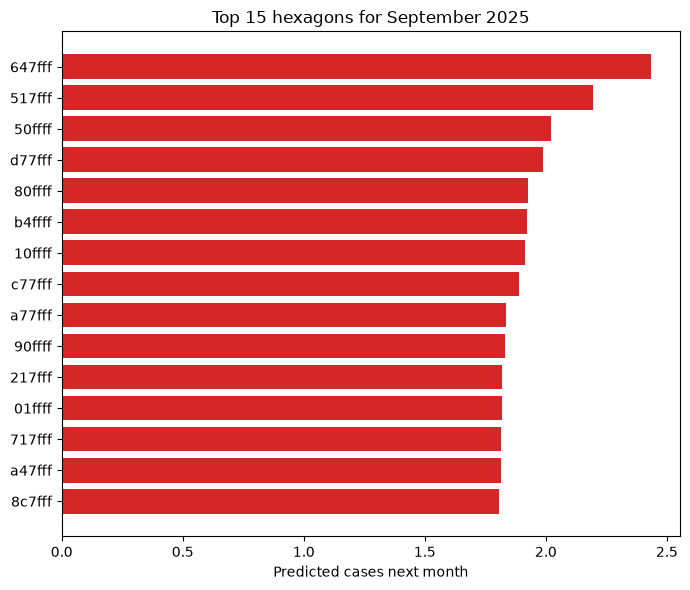

In [6]:
top15 = recs.head(15).iloc[::-1]
colors = top15["risk_tier"].map({"High": "tab:red", "Medium": "tab:orange", "Low": "tab:green"})
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(top15["h3_index"].astype(str).str[-6:], top15["predicted_cases"], color=colors)
ax.set_xlabel("Predicted cases next month")
ax.set_title(f"Top 15 hexagons for {(latest_month + pd.DateOffset(months=1)).strftime('%B %Y')}")
plt.tight_layout()
plt.show()


## Hexagon map (same idea as the main site)

The product UI paints scored H3 cells as colored polygons on a map. Locally we
write a Folium HTML file you can open without the full stack.

```bash
pip install folium
```


In [ ]:
from pipeline.viz import render_hexagon_map, attach_hex_centroids

# Attach centroids so dashboard JSON + map share the same coordinates
recs = attach_hex_centroids(recs)
save_data(recs, ARTIFACTS_DIR / "recommendations.csv")
export_dashboard_json(recs)

map_path = render_hexagon_map(
    recs,
    out_path=ARTIFACTS_DIR / "hotspot_map.html",
    title=f"Top hexagons for {(latest_month + pd.DateOffset(months=1)).strftime('%B %Y')}",
)
print("Open in a browser:", map_path)


## Output files

- `artifacts/recommendations.csv` — full ranked table
- `artifacts/dashboard_recommendations.json` — compact JSON for a map / dashboard
  (includes `h3_index`, risk tier, predicted cases, lat/lng centroids)
- `artifacts/hotspot_map.html` — interactive H3 hexagon map (open in a browser;
  same idea as the hexagon visualization on the main product site)
